# 다구치 방법론: L16 하이퍼파라미터 조합 실험
10개 파라미터를 각각 2수준으로 설정하고 L16 직교배열로 RNN·LSTM을 각각 16회 학습합니다.
공통 설정과 함수를 먼저 실행한 뒤 각 실험 셀을 독립 실행할 수 있습니다. 전체 실행 시 32개 조합과 모델별 확인 실험 1개씩을 수행합니다.
각 실험은 마지막 epoch의 검증 정확도로 비교합니다. 학습 72%·검증 8%·테스트 20%이며 시드는 123입니다.
수준별 평균 검증 정확도로 유망한 조합을 선택해 확인 실험을 합니다. 반복 시드 실험을 하지 않으므로 S/N비에 의한 강건성 분석은 수행하지 않습니다.
L16은 주효과 중심의 탐색이며 상호작용이 주효과에 섞일 수 있습니다. 전역 최적값을 보장하지 않습니다.
완료된 결과는 `taguchi_results`에 저장되어 커널을 재시작해도 재사용할 수 있습니다. 중단한 모델은 처음부터 다시 학습합니다.
각 셀의 테스트 결과는 참고용이며 조합 선택에는 사용하지 않습니다. 기존에 테스트 결과를 살펴봤으므로 독립적인 최종 평가로 해석하지 않습니다.
설계 근거: https://www.york.ac.uk/depts/maths/tables/orthogonal.htm


## 공통 설정과 L16 조합표

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
import logging
logging.getLogger('tensorflow').setLevel(logging.ERROR)
import warnings
warnings.filterwarnings('ignore', message=r'dtype\(\): align should be passed as Python or NumPy boolean.*')
import gc
import json
import time
import hashlib
from pathlib import Path
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from IPython.display import display
from tensorflow.keras import Sequential
from tensorflow.keras.datasets import reuters
from tensorflow.keras.layers import Input, Embedding, SimpleRNN, LSTM, Dropout, Dense
from tensorflow.keras.optimizers import Adam, RMSprop, SGD
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical
tf.get_logger().setLevel(logging.ERROR)
SEED = 123
OUTPUT = Path('taguchi_results')
OUTPUT.mkdir(exist_ok=True)
LEVELS = {
    'max_len': [100, 200], 'layers': [1, 2], 'units': [50, 100],
    'optimizer': ['Adam', 'RMSprop'], 'num_words': [1000, 5000],
    'embedding_dim': [32, 100], 'learning_rate': [0.0001, 0.001],
    'batch_size': [32, 100], 'dropout': [0.0, 0.2], 'epochs': [20, 40],
}
# L16 2수준 직교배열에서 10개 열을 사용하며, 모든 열 쌍의 균형을 확인합니다.
ARRAY = np.array([[1 + ((row & col).bit_count() % 2)
                   for col in range(1, 11)] for row in range(16)])
for a, b in combinations(range(10), 2):
    assert all(np.sum((ARRAY[:, a] == x) & (ARRAY[:, b] == y)) == 4
               for x in [1, 2] for y in [1, 2])
design = pd.DataFrame([
    {'run': i + 1, **{key: values[level - 1]
      for (key, values), level in zip(LEVELS.items(), levels)}}
    for i, levels in enumerate(ARRAY)
])
display(design)
design.to_csv(OUTPUT / 'design_L16.csv', index=False, encoding='utf-8-sig')


,run,max_len,layers,units,optimizer,num_words,embedding_dim,learning_rate,batch_size,dropout,epochs
0,1,100,1,50,Adam,1000,32,0.0001,32,0.0,20
1,2,200,1,100,Adam,5000,32,0.0010,32,0.2,20
2,3,100,2,100,Adam,1000,100,0.0010,32,0.0,40
3,4,200,2,50,Adam,5000,100,0.0001,32,0.2,40
4,5,100,1,50,RMSprop,5000,100,0.0010,32,0.0,20
5,6,200,1,100,RMSprop,1000,100,0.0001,32,0.2,20
6,7,100,2,100,RMSprop,5000,32,0.0001,32,0.0,40
7,8,200,2,50,RMSprop,1000,32,0.0010,32,0.2,40
8,9,100,1,50,Adam,1000,32,0.0001,100,0.2,40
9,10,200,1,100,Adam,5000,32,0.0010,100,0.0,40


## 공통 함수

In [2]:
def make_optimizer(config):
    lr = config['learning_rate']
    return {
        'Adam': lambda: Adam(learning_rate=lr),
        'RMSprop': lambda: RMSprop(learning_rate=lr),
        'SGD': lambda: SGD(learning_rate=lr),
        'MomentumSGD': lambda: SGD(learning_rate=lr, momentum=0.9),
    }[config['optimizer']]()


def build_model(model_type, config):
    recurrent_layer = SimpleRNN if model_type == 'RNN' else LSTM
    model = Sequential([
        Input(shape=(config['max_len'],), dtype='int32'),
        Embedding(config['num_words'], config['embedding_dim']),
    ])
    for layer_index in range(config['layers']):
        model.add(recurrent_layer(
            config['units'], activation='tanh',
            return_sequences=layer_index < config['layers'] - 1,
        ))
    if config['dropout'] > 0:
        model.add(Dropout(config['dropout']))
    model.add(Dense(46, activation='softmax'))
    model.compile(
        optimizer=make_optimizer(config),
        loss='categorical_crossentropy', metrics=['accuracy'],
    )
    return model


def load_experiment_data(config):
    # 어휘 수를 바꾸어도 같은 뉴스가 같은 순서로 학습·테스트에 배정되도록 시드를 고정합니다.
    (x_train, y_train), (x_test, y_test) = reuters.load_data(
        num_words=config['num_words'], test_split=0.2, seed=SEED,
    )
    x_train = pad_sequences(x_train, maxlen=config['max_len'],
                            padding='pre', truncating='pre')
    x_test = pad_sequences(x_test, maxlen=config['max_len'],
                           padding='pre', truncating='pre')
    return (x_train, to_categorical(y_train, num_classes=46),
            x_test, to_categorical(y_test, num_classes=46))




RESULTS = {}

class Progress(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        if (epoch + 1) % 5 == 0:
            print(f"  epoch {epoch + 1}: 검증 정확도={logs['val_accuracy']:.2%}", flush=True)


def run_one(family, run_id, config, phase='L16'):
    # 같은 설정이 완료되어 있으면 디스크 결과를 재사용합니다.
    fingerprint = {'version': 1, 'family': family, 'seed': SEED, **config}
    digest = hashlib.sha256(json.dumps(fingerprint, sort_keys=True).encode()).hexdigest()[:16]
    checkpoint = OUTPUT / f'{family}_{digest}.json'
    model_name = f'{family}__{phase}_{run_id}'
    if checkpoint.exists():
        saved = json.loads(checkpoint.read_text(encoding='utf-8'))
        row, history_data = saved['row'], saved['history']
        row = {**row, 'model_name': model_name, 'run': run_id, 'phase': phase}
        print(f'{model_name}: 완료 결과 재사용', flush=True)
    else:
        tf.keras.backend.clear_session()
        gc.collect()
        tf.keras.utils.set_random_seed(SEED)
        print(f'{model_name} 학습 시작: {config}', flush=True)
        started = time.perf_counter()
        x_train, y_train, x_test, y_test = load_experiment_data(config)
        model = build_model(family, config)
        history = model.fit(x_train, y_train, validation_split=0.10,
                            epochs=config['epochs'], batch_size=config['batch_size'],
                            shuffle=True, verbose=0, callbacks=[Progress()])
        history_data = {key: [float(v) for v in values] for key, values in history.history.items()}
        test = model.evaluate(x_test, y_test, verbose=0, return_dict=True)
        row = dict(model_type=family, model_name=model_name, run=run_id, phase=phase,
                   **config, train_accuracy=history_data['accuracy'][-1],
                   val_accuracy=history_data['val_accuracy'][-1],
                   val_loss=history_data['val_loss'][-1],
                   test_accuracy=float(test['accuracy']), test_loss=float(test['loss']),
                   seconds=time.perf_counter() - started)
        assert all(np.isfinite(row[key]) for key in ['val_accuracy', 'val_loss', 'test_accuracy', 'test_loss'])
        checkpoint.write_text(json.dumps({'row': row, 'history': history_data}, ensure_ascii=False, indent=2), encoding='utf-8')
        del model
        tf.keras.backend.clear_session()
        gc.collect()
    RESULTS[model_name] = row
    pd.DataFrame(RESULTS.values()).to_csv(OUTPUT / 'results.csv', index=False, encoding='utf-8-sig')
    print(f"{model_name}: 검증={row['val_accuracy']:.2%}, 테스트={row['test_accuracy']:.2%}, "
          f"손실={row['test_loss']:.4f}, 시간={row['seconds']:.1f}초", flush=True)
    fig, ax = plt.subplots(figsize=(8, 5))
    epochs = range(1, len(history_data['accuracy']) + 1)
    ax.plot(epochs, history_data['accuracy'], 'b--', label=f'{model_name}-train')
    ax.plot(epochs, history_data['val_accuracy'], 'b-', label=f'{model_name}-valid')
    ax.set(xlabel='Epoch', ylabel='Accuracy', ylim=(0, 1), title=f'{model_name}: Accuracy trace plot')
    ax.legend(loc='lower right')
    fig.tight_layout()
    fig.savefig(OUTPUT / f'{model_name}_accuracy.png', dpi=120)
    plt.show()
    plt.close(fig)
    return row


def run_design(family, number):
    record = design.iloc[number - 1].to_dict()
    config = {key: record[key] for key in LEVELS}
    return run_one(family, f'{number:02d}', config)


## RNN — 조합 01

RNN__L16_01 학습 시작: {'max_len': 100, 'layers': 1, 'units': 50, 'optimizer': 'Adam', 'num_words': 1000, 'embedding_dim': 32, 'learning_rate': 0.0001, 'batch_size': 32, 'dropout': 0.0, 'epochs': 20}


  epoch 5: 검증 정확도=36.37%


  epoch 10: 검증 정확도=49.05%


  epoch 15: 검증 정확도=51.72%


  epoch 20: 검증 정확도=58.06%


RNN__L16_01: 검증=58.06%, 테스트=54.59%, 손실=1.7993, 시간=33.7초


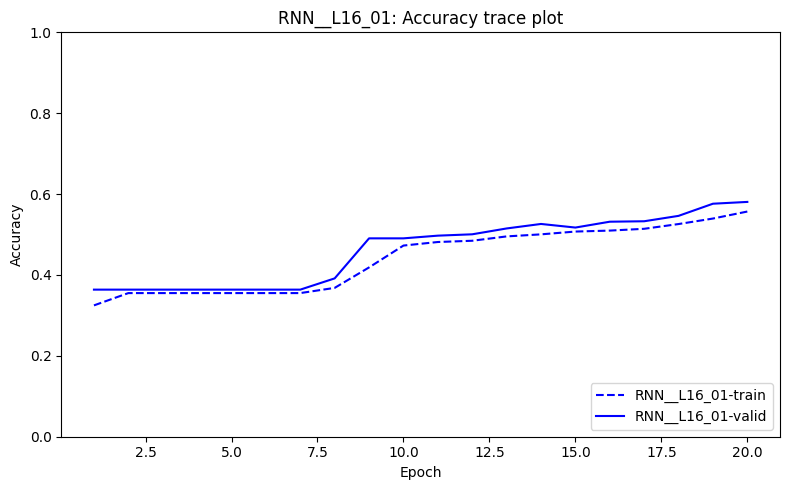

In [3]:
result_rnn_01 = run_design('RNN', 1)


## RNN — 조합 02

RNN__L16_02 학습 시작: {'max_len': 200, 'layers': 1, 'units': 100, 'optimizer': 'Adam', 'num_words': 5000, 'embedding_dim': 32, 'learning_rate': 0.001, 'batch_size': 32, 'dropout': 0.2, 'epochs': 20}


  epoch 5: 검증 정확도=48.72%


  epoch 10: 검증 정확도=41.94%


  epoch 15: 검증 정확도=45.05%


  epoch 20: 검증 정확도=52.17%


RNN__L16_02: 검증=52.17%, 테스트=48.04%, 손실=1.9416, 시간=91.8초


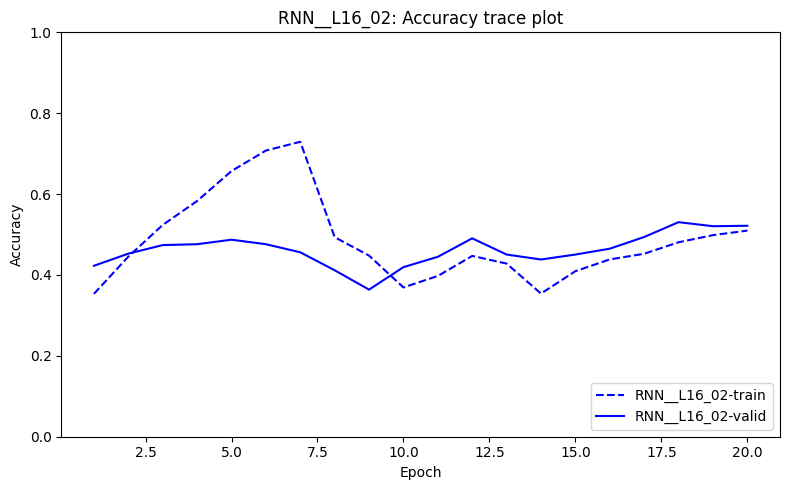

In [4]:
result_rnn_02 = run_design('RNN', 2)


## RNN — 조합 03

RNN__L16_03 학습 시작: {'max_len': 100, 'layers': 2, 'units': 100, 'optimizer': 'Adam', 'num_words': 1000, 'embedding_dim': 100, 'learning_rate': 0.001, 'batch_size': 32, 'dropout': 0.0, 'epochs': 40}


  epoch 5: 검증 정확도=50.28%


  epoch 10: 검증 정확도=50.50%


  epoch 15: 검증 정확도=50.95%


  epoch 20: 검증 정확도=48.39%


  epoch 25: 검증 정확도=51.95%


  epoch 30: 검증 정확도=52.39%


  epoch 35: 검증 정확도=52.73%


  epoch 40: 검증 정확도=52.95%


RNN__L16_03: 검증=52.95%, 테스트=48.09%, 손실=4.0915, 시간=151.5초


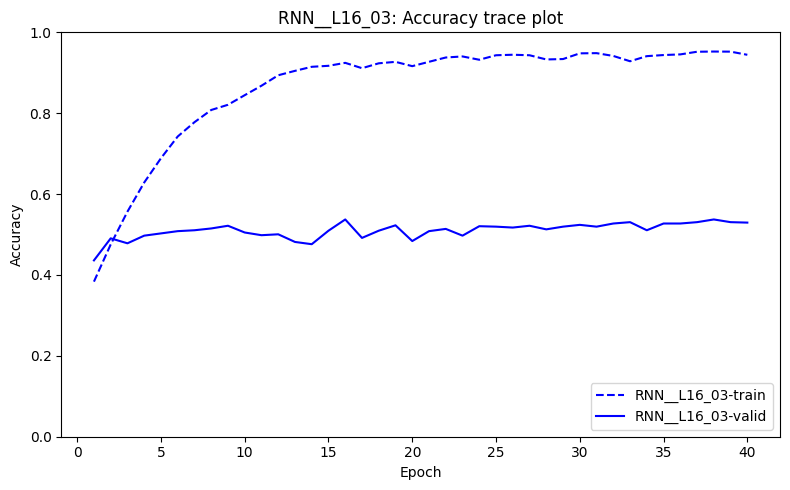

In [5]:
result_rnn_03 = run_design('RNN', 3)


## RNN — 조합 04

RNN__L16_04 학습 시작: {'max_len': 200, 'layers': 2, 'units': 50, 'optimizer': 'Adam', 'num_words': 5000, 'embedding_dim': 100, 'learning_rate': 0.0001, 'batch_size': 32, 'dropout': 0.2, 'epochs': 40}


  epoch 5: 검증 정확도=59.84%


  epoch 10: 검증 정확도=60.18%


  epoch 15: 검증 정확도=59.84%


  epoch 20: 검증 정확도=61.51%


  epoch 25: 검증 정확도=60.18%


  epoch 30: 검증 정확도=59.62%


  epoch 35: 검증 정확도=59.84%


  epoch 40: 검증 정확도=59.96%


RNN__L16_04: 검증=59.96%, 테스트=56.68%, 손실=2.2278, 시간=368.5초


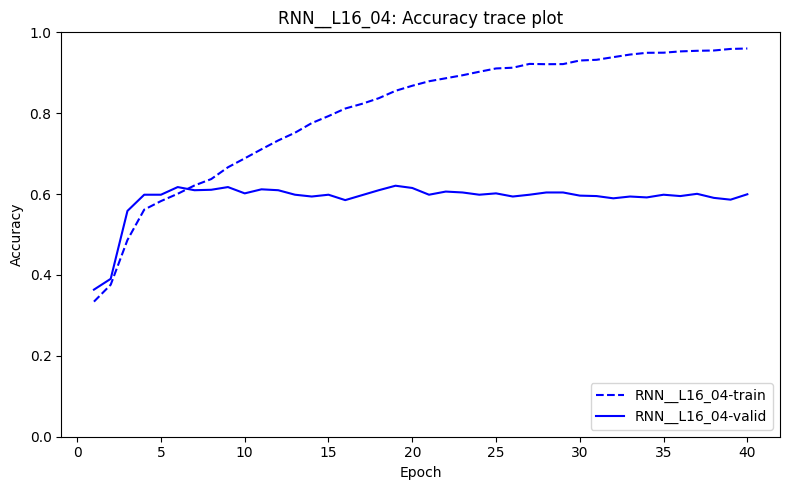

In [6]:
result_rnn_04 = run_design('RNN', 4)


## RNN — 조합 05

RNN__L16_05 학습 시작: {'max_len': 100, 'layers': 1, 'units': 50, 'optimizer': 'RMSprop', 'num_words': 5000, 'embedding_dim': 100, 'learning_rate': 0.001, 'batch_size': 32, 'dropout': 0.0, 'epochs': 20}


  epoch 5: 검증 정확도=60.07%


  epoch 10: 검증 정확도=57.17%


  epoch 15: 검증 정확도=54.95%


  epoch 20: 검증 정확도=55.28%


RNN__L16_05: 검증=55.28%, 테스트=53.03%, 손실=2.5531, 시간=64.1초


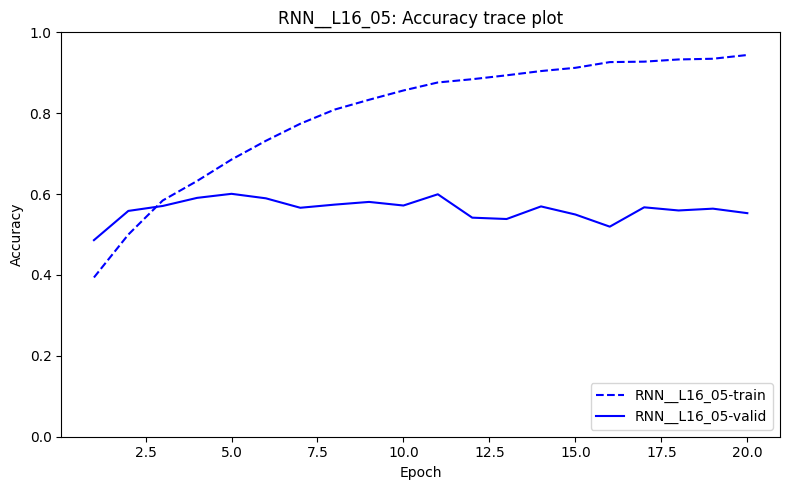

In [7]:
result_rnn_05 = run_design('RNN', 5)


## RNN — 조합 06

RNN__L16_06 학습 시작: {'max_len': 200, 'layers': 1, 'units': 100, 'optimizer': 'RMSprop', 'num_words': 1000, 'embedding_dim': 100, 'learning_rate': 0.0001, 'batch_size': 32, 'dropout': 0.2, 'epochs': 20}


  epoch 5: 검증 정확도=52.61%


  epoch 10: 검증 정확도=61.62%


  epoch 15: 검증 정확도=63.29%


  epoch 20: 검증 정확도=62.63%


RNN__L16_06: 검증=62.63%, 테스트=59.66%, 손실=1.6472, 시간=112.7초


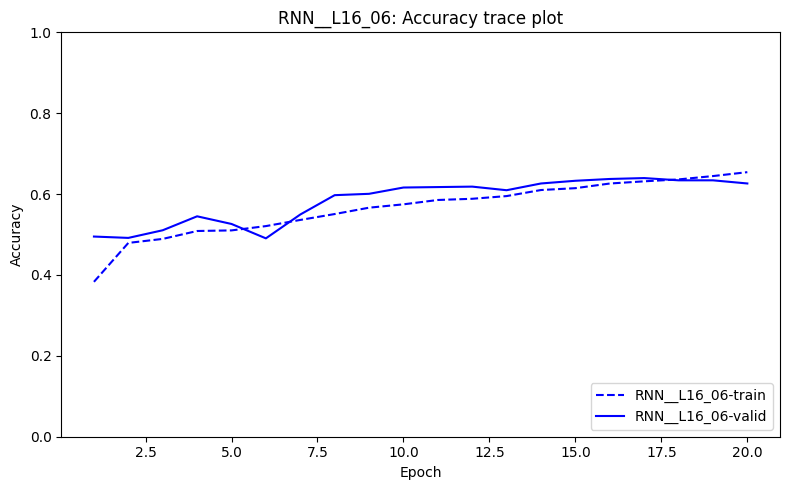

In [8]:
result_rnn_06 = run_design('RNN', 6)


## RNN — 조합 07

RNN__L16_07 학습 시작: {'max_len': 100, 'layers': 2, 'units': 100, 'optimizer': 'RMSprop', 'num_words': 5000, 'embedding_dim': 32, 'learning_rate': 0.0001, 'batch_size': 32, 'dropout': 0.0, 'epochs': 40}


  epoch 5: 검증 정확도=57.06%


  epoch 10: 검증 정확도=58.51%


  epoch 15: 검증 정확도=60.29%


  epoch 20: 검증 정확도=60.51%


  epoch 25: 검증 정확도=58.95%


  epoch 30: 검증 정확도=57.51%


  epoch 35: 검증 정확도=57.84%


  epoch 40: 검증 정확도=56.95%


RNN__L16_07: 검증=56.95%, 테스트=54.99%, 손실=2.0599, 시간=205.4초


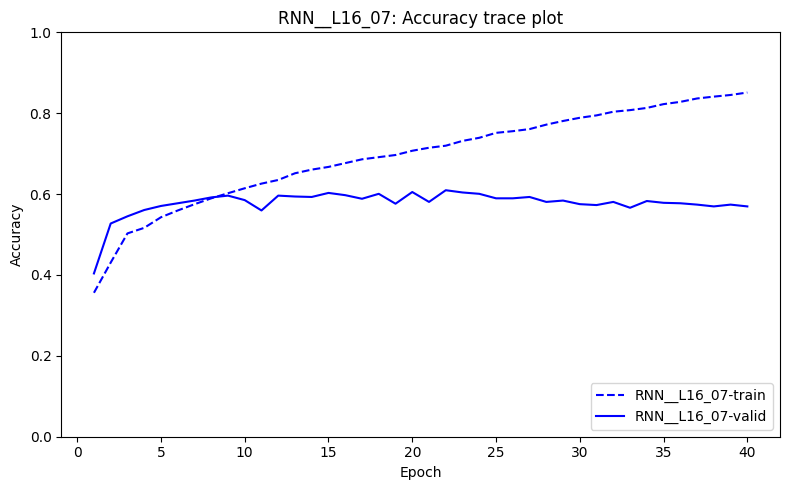

In [9]:
result_rnn_07 = run_design('RNN', 7)


## RNN — 조합 08

RNN__L16_08 학습 시작: {'max_len': 200, 'layers': 2, 'units': 50, 'optimizer': 'RMSprop', 'num_words': 1000, 'embedding_dim': 32, 'learning_rate': 0.001, 'batch_size': 32, 'dropout': 0.2, 'epochs': 40}


  epoch 5: 검증 정확도=56.73%


  epoch 10: 검증 정확도=56.62%


  epoch 15: 검증 정확도=55.51%


  epoch 20: 검증 정확도=55.84%


  epoch 25: 검증 정확도=56.06%


  epoch 30: 검증 정확도=52.95%


  epoch 35: 검증 정확도=53.62%


  epoch 40: 검증 정확도=53.62%


RNN__L16_08: 검증=53.62%, 테스트=48.89%, 손실=3.0501, 시간=353.3초


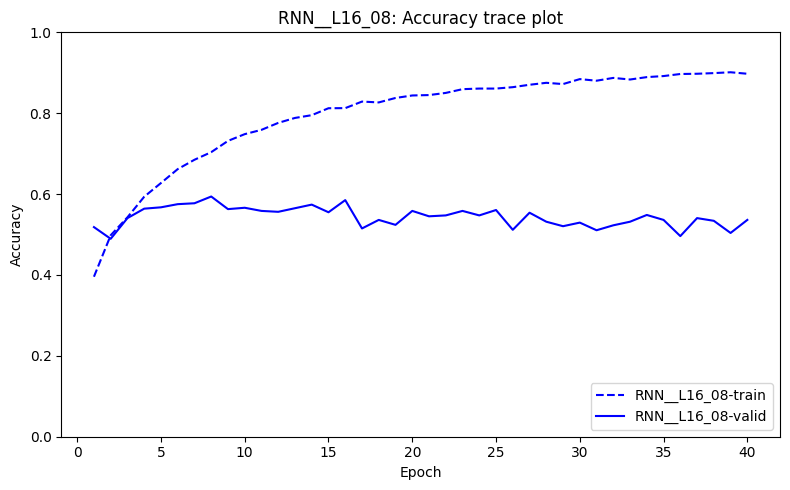

In [10]:
result_rnn_08 = run_design('RNN', 8)


## RNN — 조합 09

RNN__L16_09 학습 시작: {'max_len': 100, 'layers': 1, 'units': 50, 'optimizer': 'Adam', 'num_words': 1000, 'embedding_dim': 32, 'learning_rate': 0.0001, 'batch_size': 100, 'dropout': 0.2, 'epochs': 40}


  epoch 5: 검증 정확도=36.37%


  epoch 10: 검증 정확도=36.37%


  epoch 15: 검증 정확도=36.37%


  epoch 20: 검증 정확도=48.16%


  epoch 25: 검증 정확도=51.61%


  epoch 30: 검증 정확도=56.95%


  epoch 35: 검증 정확도=59.18%


  epoch 40: 검증 정확도=59.29%


RNN__L16_09: 검증=59.29%, 테스트=56.46%, 손실=1.7677, 시간=46.2초


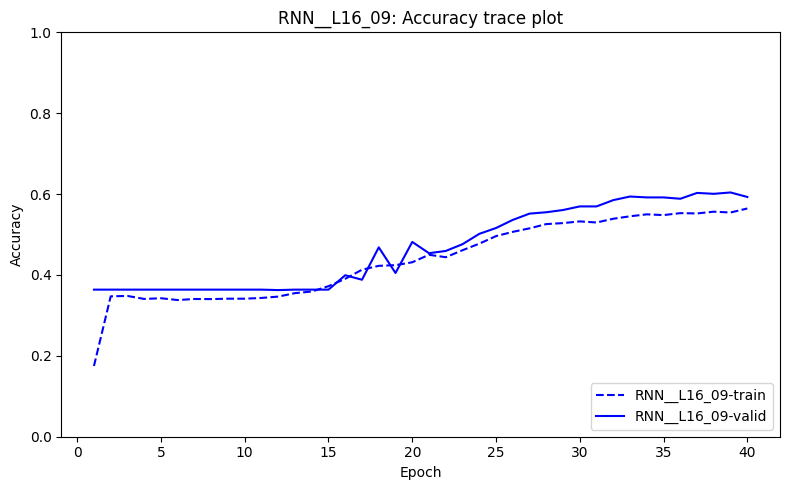

In [11]:
result_rnn_09 = run_design('RNN', 9)


## RNN — 조합 10

RNN__L16_10 학습 시작: {'max_len': 200, 'layers': 1, 'units': 100, 'optimizer': 'Adam', 'num_words': 5000, 'embedding_dim': 32, 'learning_rate': 0.001, 'batch_size': 100, 'dropout': 0.0, 'epochs': 40}


  epoch 5: 검증 정확도=50.83%


  epoch 10: 검증 정확도=54.17%


  epoch 15: 검증 정확도=47.39%


  epoch 20: 검증 정확도=51.50%


  epoch 25: 검증 정확도=51.06%


  epoch 30: 검증 정확도=47.72%


  epoch 35: 검증 정확도=48.50%


  epoch 40: 검증 정확도=49.72%


RNN__L16_10: 검증=49.72%, 테스트=44.52%, 손실=3.5124, 시간=129.6초


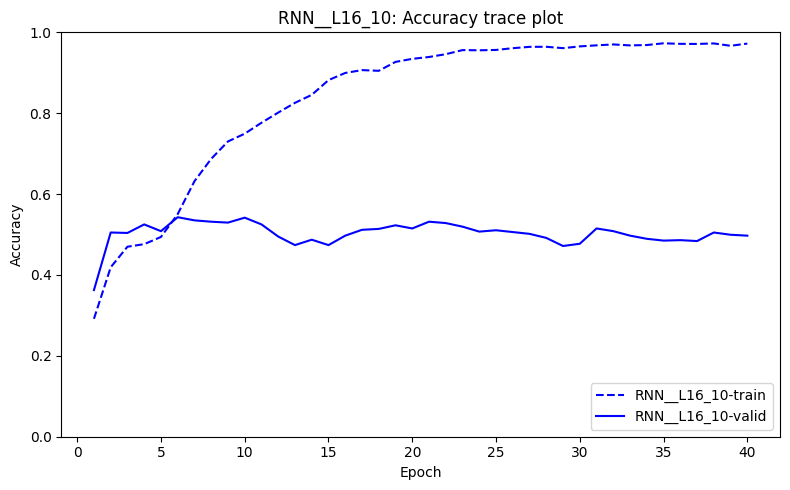

In [12]:
result_rnn_10 = run_design('RNN', 10)


## RNN — 조합 11

RNN__L16_11 학습 시작: {'max_len': 100, 'layers': 2, 'units': 100, 'optimizer': 'Adam', 'num_words': 1000, 'embedding_dim': 100, 'learning_rate': 0.001, 'batch_size': 100, 'dropout': 0.2, 'epochs': 20}


  epoch 5: 검증 정확도=57.51%


  epoch 10: 검증 정확도=54.73%


  epoch 15: 검증 정확도=58.73%


  epoch 20: 검증 정확도=54.17%


RNN__L16_11: 검증=54.17%, 테스트=50.58%, 손실=3.0820, 시간=90.4초


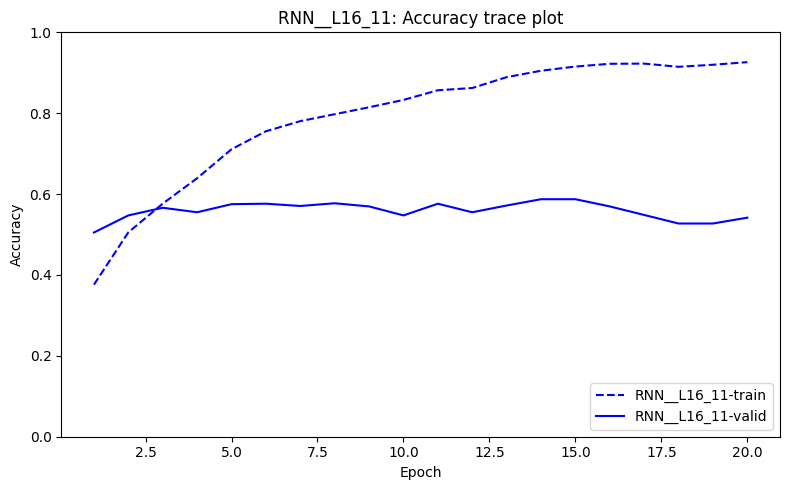

In [13]:
result_rnn_11 = run_design('RNN', 11)


## RNN — 조합 12

RNN__L16_12 학습 시작: {'max_len': 200, 'layers': 2, 'units': 50, 'optimizer': 'Adam', 'num_words': 5000, 'embedding_dim': 100, 'learning_rate': 0.0001, 'batch_size': 100, 'dropout': 0.0, 'epochs': 20}


  epoch 5: 검증 정확도=45.61%


  epoch 10: 검증 정확도=59.51%


  epoch 15: 검증 정확도=59.73%


  epoch 20: 검증 정확도=60.07%


RNN__L16_12: 검증=60.07%, 테스트=57.88%, 손실=1.7120, 시간=116.2초


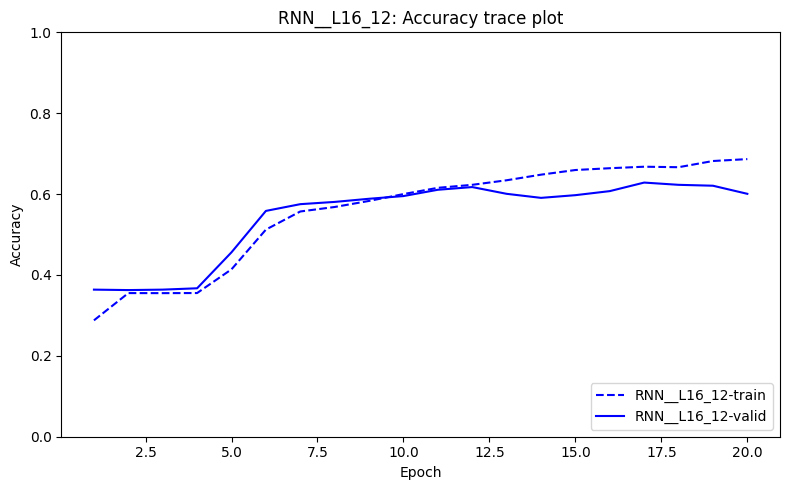

In [14]:
result_rnn_12 = run_design('RNN', 12)


## RNN — 조합 13

RNN__L16_13 학습 시작: {'max_len': 100, 'layers': 1, 'units': 50, 'optimizer': 'RMSprop', 'num_words': 5000, 'embedding_dim': 100, 'learning_rate': 0.001, 'batch_size': 100, 'dropout': 0.2, 'epochs': 40}


  epoch 5: 검증 정확도=59.29%


  epoch 10: 검증 정확도=57.29%


  epoch 15: 검증 정확도=58.62%


  epoch 20: 검증 정확도=59.07%


  epoch 25: 검증 정확도=57.84%


  epoch 30: 검증 정확도=58.62%


  epoch 35: 검증 정확도=58.29%


  epoch 40: 검증 정확도=58.84%


RNN__L16_13: 검증=58.84%, 테스트=53.12%, 손실=2.9159, 시간=74.2초


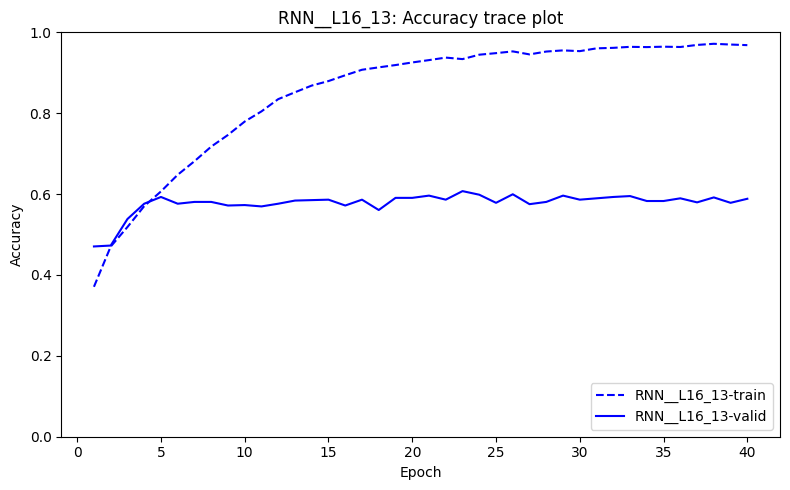

In [15]:
result_rnn_13 = run_design('RNN', 13)


## RNN — 조합 14

RNN__L16_14 학습 시작: {'max_len': 200, 'layers': 1, 'units': 100, 'optimizer': 'RMSprop', 'num_words': 1000, 'embedding_dim': 100, 'learning_rate': 0.0001, 'batch_size': 100, 'dropout': 0.0, 'epochs': 40}


  epoch 5: 검증 정확도=51.39%


  epoch 10: 검증 정확도=52.61%


  epoch 15: 검증 정확도=57.84%


  epoch 20: 검증 정확도=58.29%


  epoch 25: 검증 정확도=58.51%


  epoch 30: 검증 정확도=62.51%


  epoch 35: 검증 정확도=64.40%


  epoch 40: 검증 정확도=66.74%


RNN__L16_14: 검증=66.74%, 테스트=62.73%, 손실=1.5233, 시간=218.4초


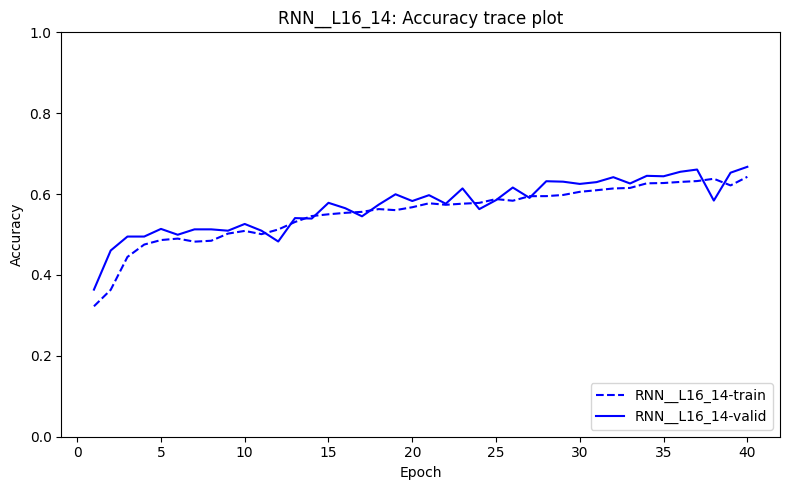

In [16]:
result_rnn_14 = run_design('RNN', 14)


## RNN — 조합 15

RNN__L16_15 학습 시작: {'max_len': 100, 'layers': 2, 'units': 100, 'optimizer': 'RMSprop', 'num_words': 5000, 'embedding_dim': 32, 'learning_rate': 0.0001, 'batch_size': 100, 'dropout': 0.2, 'epochs': 20}


  epoch 5: 검증 정확도=54.62%


  epoch 10: 검증 정확도=59.40%


  epoch 15: 검증 정확도=59.51%


  epoch 20: 검증 정확도=59.18%


RNN__L16_15: 검증=59.18%, 테스트=56.23%, 손실=1.7430, 시간=72.8초


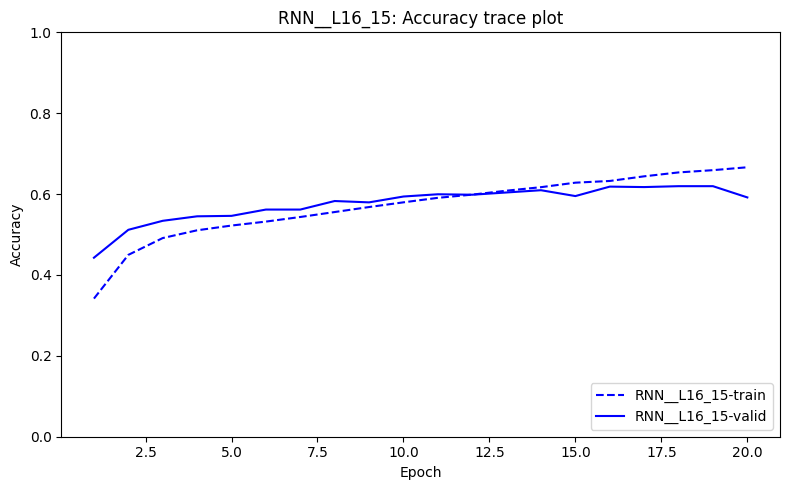

In [17]:
result_rnn_15 = run_design('RNN', 15)


## RNN — 조합 16

RNN__L16_16 학습 시작: {'max_len': 200, 'layers': 2, 'units': 50, 'optimizer': 'RMSprop', 'num_words': 1000, 'embedding_dim': 32, 'learning_rate': 0.001, 'batch_size': 100, 'dropout': 0.0, 'epochs': 20}


  epoch 5: 검증 정확도=49.72%


  epoch 10: 검증 정확도=57.73%


  epoch 15: 검증 정확도=55.28%


  epoch 20: 검증 정확도=55.28%


RNN__L16_16: 검증=55.28%, 테스트=52.98%, 손실=2.4485, 시간=80.6초


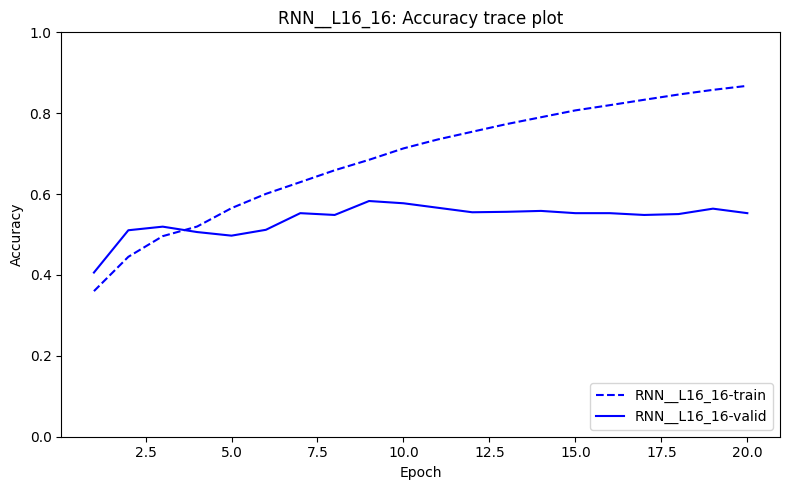

In [18]:
result_rnn_16 = run_design('RNN', 16)


## LSTM — 조합 01

LSTM__L16_01 학습 시작: {'max_len': 100, 'layers': 1, 'units': 50, 'optimizer': 'Adam', 'num_words': 1000, 'embedding_dim': 32, 'learning_rate': 0.0001, 'batch_size': 32, 'dropout': 0.0, 'epochs': 20}


  epoch 5: 검증 정확도=51.06%


  epoch 10: 검증 정확도=58.84%


  epoch 15: 검증 정확도=58.95%


  epoch 20: 검증 정확도=59.51%


LSTM__L16_01: 검증=59.51%, 테스트=54.85%, 손실=1.7248, 시간=118.0초


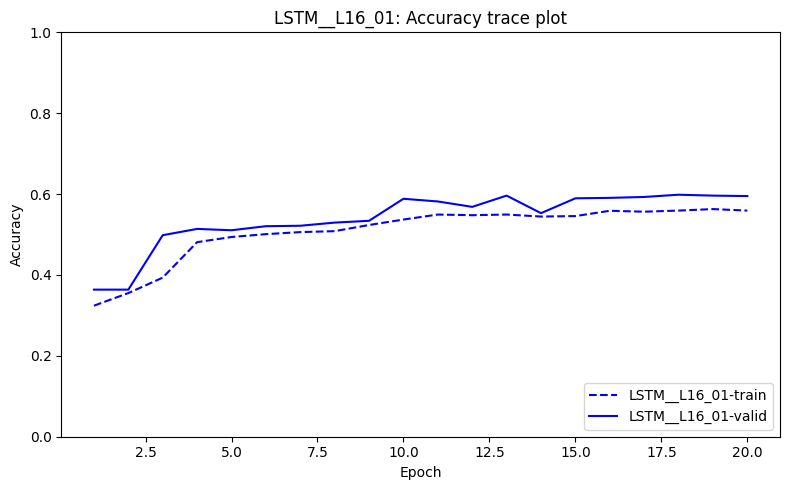

In [19]:
result_lstm_01 = run_design('LSTM', 1)


## LSTM — 조합 02

LSTM__L16_02 학습 시작: {'max_len': 200, 'layers': 1, 'units': 100, 'optimizer': 'Adam', 'num_words': 5000, 'embedding_dim': 32, 'learning_rate': 0.001, 'batch_size': 32, 'dropout': 0.2, 'epochs': 20}


  epoch 5: 검증 정확도=64.63%


  epoch 10: 검증 정확도=69.30%


  epoch 15: 검증 정확도=69.86%


  epoch 20: 검증 정확도=69.08%


LSTM__L16_02: 검증=69.08%, 테스트=67.81%, 손실=1.6269, 시간=341.0초


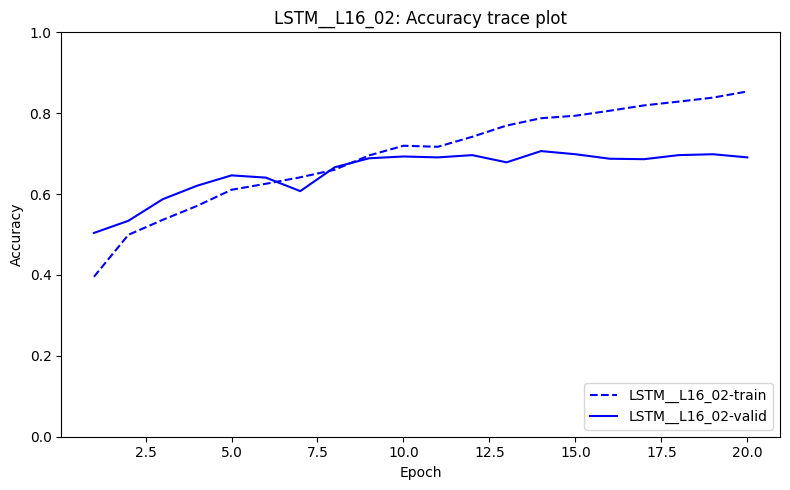

In [20]:
result_lstm_02 = run_design('LSTM', 2)


## LSTM — 조합 03

LSTM__L16_03 학습 시작: {'max_len': 100, 'layers': 2, 'units': 100, 'optimizer': 'Adam', 'num_words': 1000, 'embedding_dim': 100, 'learning_rate': 0.001, 'batch_size': 32, 'dropout': 0.0, 'epochs': 40}


  epoch 5: 검증 정확도=65.85%


  epoch 10: 검증 정확도=71.64%


  epoch 15: 검증 정확도=72.64%


  epoch 20: 검증 정확도=71.86%


  epoch 25: 검증 정확도=74.19%


  epoch 30: 검증 정확도=74.75%


  epoch 35: 검증 정확도=74.64%


  epoch 40: 검증 정확도=72.75%


LSTM__L16_03: 검증=72.75%, 테스트=68.70%, 손실=1.6753, 시간=623.4초


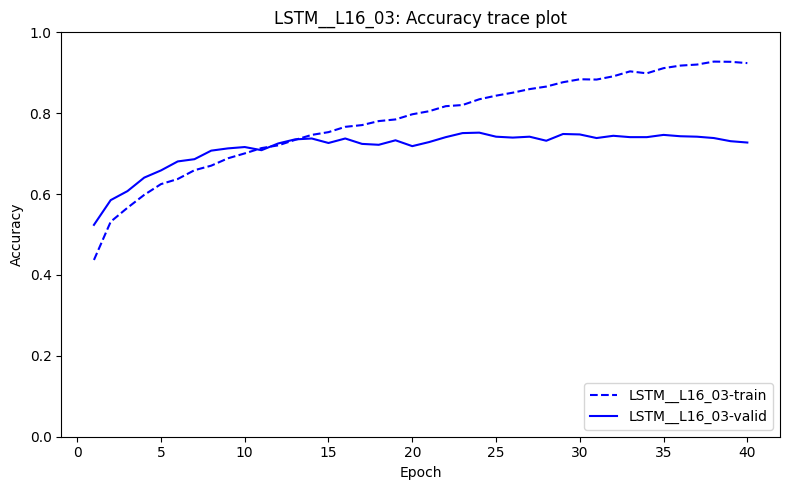

In [21]:
result_lstm_03 = run_design('LSTM', 3)


## LSTM — 조합 04

LSTM__L16_04 학습 시작: {'max_len': 200, 'layers': 2, 'units': 50, 'optimizer': 'Adam', 'num_words': 5000, 'embedding_dim': 100, 'learning_rate': 0.0001, 'batch_size': 32, 'dropout': 0.2, 'epochs': 40}


  epoch 5: 검증 정확도=59.51%


  epoch 10: 검증 정확도=36.82%


  epoch 15: 검증 정확도=57.84%


  epoch 20: 검증 정확도=57.84%


  epoch 25: 검증 정확도=60.07%


  epoch 30: 검증 정확도=60.51%


  epoch 35: 검증 정확도=59.40%


  epoch 40: 검증 정확도=60.29%


LSTM__L16_04: 검증=60.29%, 테스트=58.99%, 손실=1.6617, 시간=774.9초


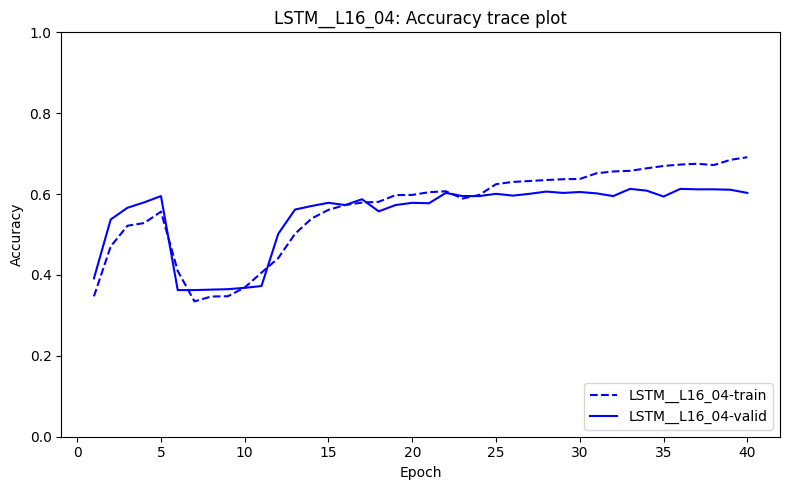

In [22]:
result_lstm_04 = run_design('LSTM', 4)


## LSTM — 조합 05

LSTM__L16_05 학습 시작: {'max_len': 100, 'layers': 1, 'units': 50, 'optimizer': 'RMSprop', 'num_words': 5000, 'embedding_dim': 100, 'learning_rate': 0.001, 'batch_size': 32, 'dropout': 0.0, 'epochs': 20}


  epoch 5: 검증 정확도=66.30%


  epoch 10: 검증 정확도=72.75%


  epoch 15: 검증 정확도=72.64%


  epoch 20: 검증 정확도=71.41%


LSTM__L16_05: 검증=71.41%, 테스트=69.59%, 손실=1.4335, 시간=111.4초


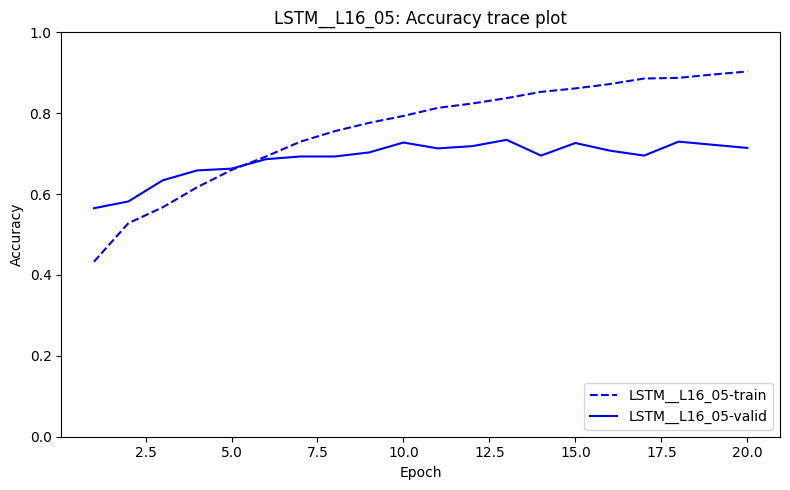

In [23]:
result_lstm_05 = run_design('LSTM', 5)


## LSTM — 조합 06

LSTM__L16_06 학습 시작: {'max_len': 200, 'layers': 1, 'units': 100, 'optimizer': 'RMSprop', 'num_words': 1000, 'embedding_dim': 100, 'learning_rate': 0.0001, 'batch_size': 32, 'dropout': 0.2, 'epochs': 20}


  epoch 5: 검증 정확도=52.39%


  epoch 10: 검증 정확도=55.73%


  epoch 15: 검증 정확도=60.40%


  epoch 20: 검증 정확도=62.40%


LSTM__L16_06: 검증=62.40%, 테스트=57.70%, 손실=1.6397, 시간=334.2초


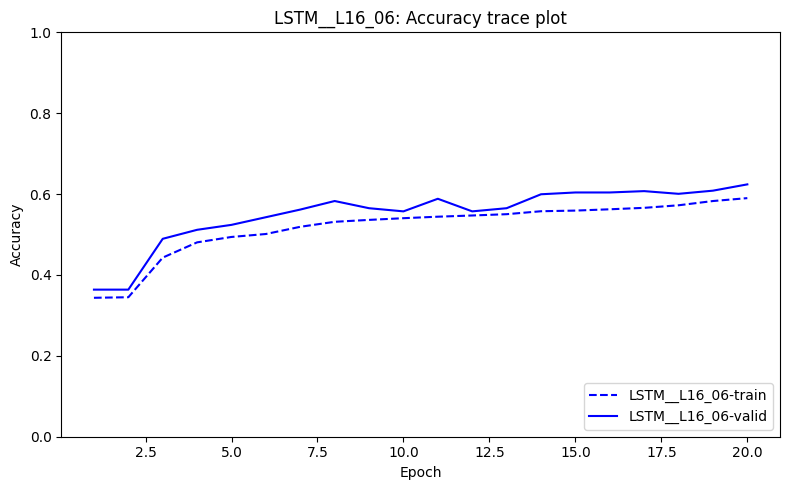

In [24]:
result_lstm_06 = run_design('LSTM', 6)


## LSTM — 조합 07

LSTM__L16_07 학습 시작: {'max_len': 100, 'layers': 2, 'units': 100, 'optimizer': 'RMSprop', 'num_words': 5000, 'embedding_dim': 32, 'learning_rate': 0.0001, 'batch_size': 32, 'dropout': 0.0, 'epochs': 40}


  epoch 5: 검증 정확도=57.73%


  epoch 10: 검증 정확도=60.18%


  epoch 15: 검증 정확도=60.40%


  epoch 20: 검증 정확도=57.62%


  epoch 25: 검증 정확도=55.73%


  epoch 30: 검증 정확도=57.06%


  epoch 35: 검증 정확도=57.95%


  epoch 40: 검증 정확도=56.84%


LSTM__L16_07: 검증=56.84%, 테스트=55.39%, 손실=1.7986, 시간=675.0초


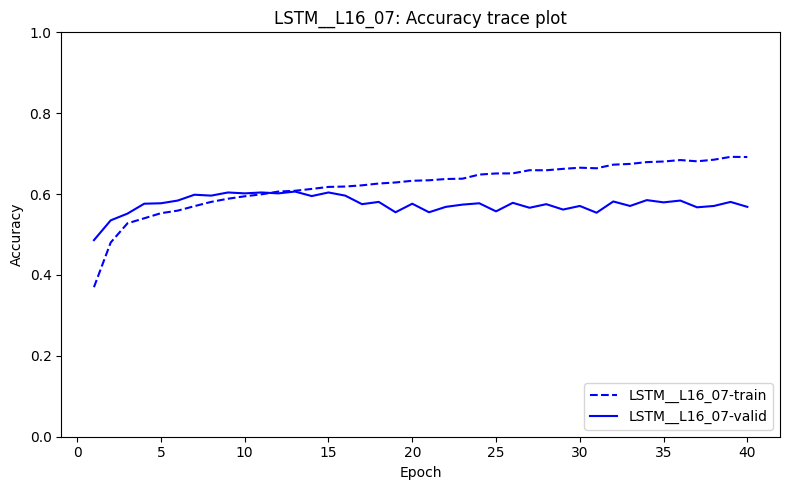

In [25]:
result_lstm_07 = run_design('LSTM', 7)


## LSTM — 조합 08

LSTM__L16_08 학습 시작: {'max_len': 200, 'layers': 2, 'units': 50, 'optimizer': 'RMSprop', 'num_words': 1000, 'embedding_dim': 32, 'learning_rate': 0.001, 'batch_size': 32, 'dropout': 0.2, 'epochs': 40}


  epoch 5: 검증 정확도=61.40%


  epoch 10: 검증 정확도=66.30%


  epoch 15: 검증 정확도=66.96%


  epoch 20: 검증 정확도=71.75%


  epoch 25: 검증 정확도=73.64%


  epoch 30: 검증 정확도=73.75%


  epoch 35: 검증 정확도=74.64%


  epoch 40: 검증 정확도=74.64%


LSTM__L16_08: 검증=74.64%, 테스트=71.73%, 손실=1.2689, 시간=808.9초


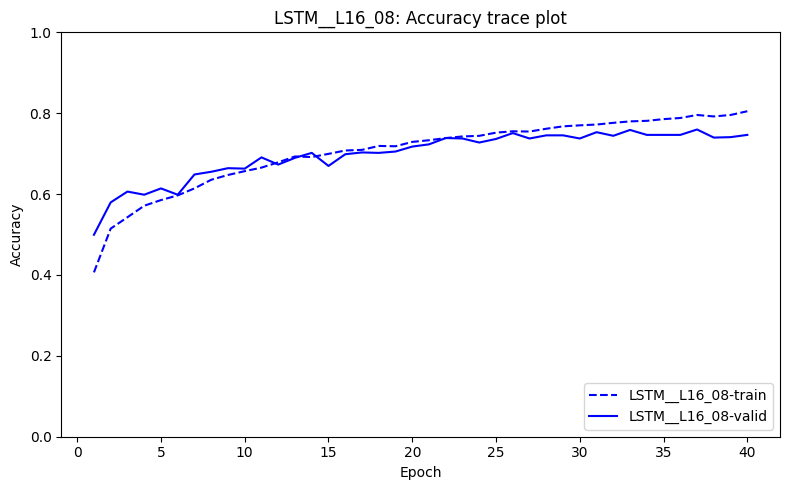

In [26]:
result_lstm_08 = run_design('LSTM', 8)


## LSTM — 조합 09

LSTM__L16_09 학습 시작: {'max_len': 100, 'layers': 1, 'units': 50, 'optimizer': 'Adam', 'num_words': 1000, 'embedding_dim': 32, 'learning_rate': 0.0001, 'batch_size': 100, 'dropout': 0.2, 'epochs': 40}


  epoch 5: 검증 정확도=44.72%


  epoch 10: 검증 정확도=52.50%


  epoch 15: 검증 정확도=57.84%


  epoch 20: 검증 정확도=57.73%


  epoch 25: 검증 정확도=62.07%


  epoch 30: 검증 정확도=63.63%


  epoch 35: 검증 정확도=62.96%


  epoch 40: 검증 정확도=63.85%


LSTM__L16_09: 검증=63.85%, 테스트=59.57%, 손실=1.6582, 시간=120.3초


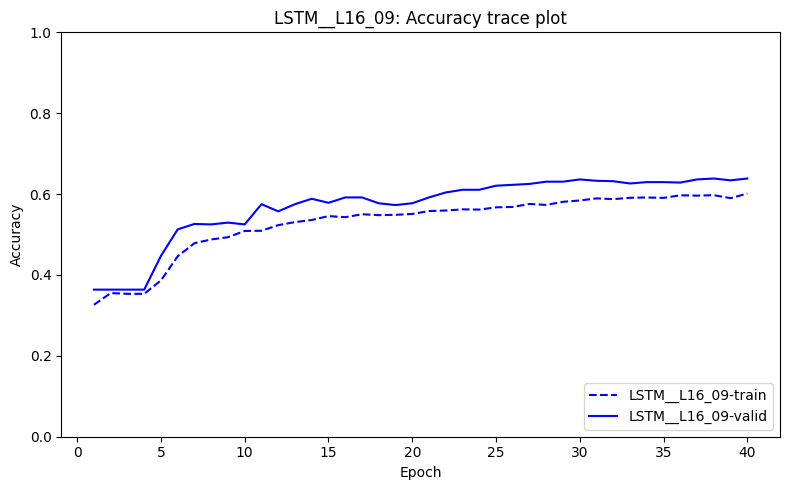

In [27]:
result_lstm_09 = run_design('LSTM', 9)


## LSTM — 조합 10

LSTM__L16_10 학습 시작: {'max_len': 200, 'layers': 1, 'units': 100, 'optimizer': 'Adam', 'num_words': 5000, 'embedding_dim': 32, 'learning_rate': 0.001, 'batch_size': 100, 'dropout': 0.0, 'epochs': 40}


  epoch 5: 검증 정확도=53.17%


  epoch 10: 검증 정확도=59.62%


  epoch 15: 검증 정확도=64.63%


  epoch 20: 검증 정확도=67.30%


  epoch 25: 검증 정확도=69.52%


  epoch 30: 검증 정확도=70.30%


  epoch 35: 검증 정확도=71.41%


  epoch 40: 검증 정확도=70.75%


LSTM__L16_10: 검증=70.75%, 테스트=68.92%, 손실=1.6540, 시간=476.7초


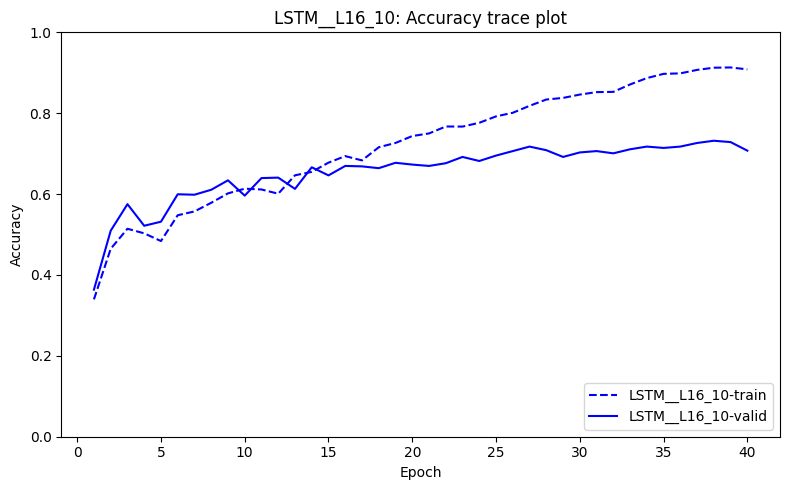

In [28]:
result_lstm_10 = run_design('LSTM', 10)


## LSTM — 조합 11

LSTM__L16_11 학습 시작: {'max_len': 100, 'layers': 2, 'units': 100, 'optimizer': 'Adam', 'num_words': 1000, 'embedding_dim': 100, 'learning_rate': 0.001, 'batch_size': 100, 'dropout': 0.2, 'epochs': 20}


  epoch 5: 검증 정확도=58.51%


  epoch 10: 검증 정확도=64.85%


  epoch 15: 검증 정확도=68.30%


  epoch 20: 검증 정확도=69.63%


LSTM__L16_11: 검증=69.63%, 테스트=67.85%, 손실=1.2860, 시간=234.5초


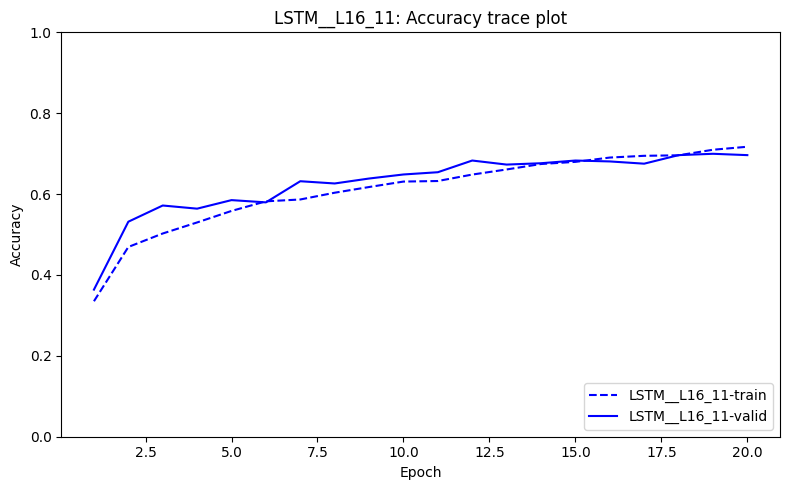

In [29]:
result_lstm_11 = run_design('LSTM', 11)


## LSTM — 조합 12

LSTM__L16_12 학습 시작: {'max_len': 200, 'layers': 2, 'units': 50, 'optimizer': 'Adam', 'num_words': 5000, 'embedding_dim': 100, 'learning_rate': 0.0001, 'batch_size': 100, 'dropout': 0.0, 'epochs': 20}


  epoch 5: 검증 정확도=52.61%


  epoch 10: 검증 정확도=59.29%


  epoch 15: 검증 정확도=62.07%


  epoch 20: 검증 정확도=63.07%


LSTM__L16_12: 검증=63.07%, 테스트=60.55%, 손실=1.6170, 시간=287.3초


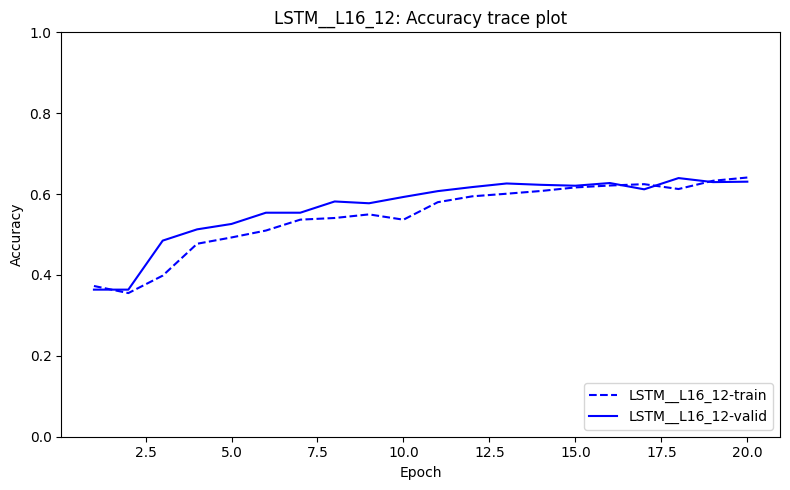

In [30]:
result_lstm_12 = run_design('LSTM', 12)


## LSTM — 조합 13

LSTM__L16_13 학습 시작: {'max_len': 100, 'layers': 1, 'units': 50, 'optimizer': 'RMSprop', 'num_words': 5000, 'embedding_dim': 100, 'learning_rate': 0.001, 'batch_size': 100, 'dropout': 0.2, 'epochs': 40}


  epoch 5: 검증 정확도=59.84%


  epoch 10: 검증 정확도=67.07%


  epoch 15: 검증 정확도=68.85%


  epoch 20: 검증 정확도=70.63%


  epoch 25: 검증 정확도=71.52%


  epoch 30: 검증 정확도=70.86%


  epoch 35: 검증 정확도=71.64%


  epoch 40: 검증 정확도=71.08%


LSTM__L16_13: 검증=71.08%, 테스트=69.46%, 손실=1.5724, 시간=119.3초


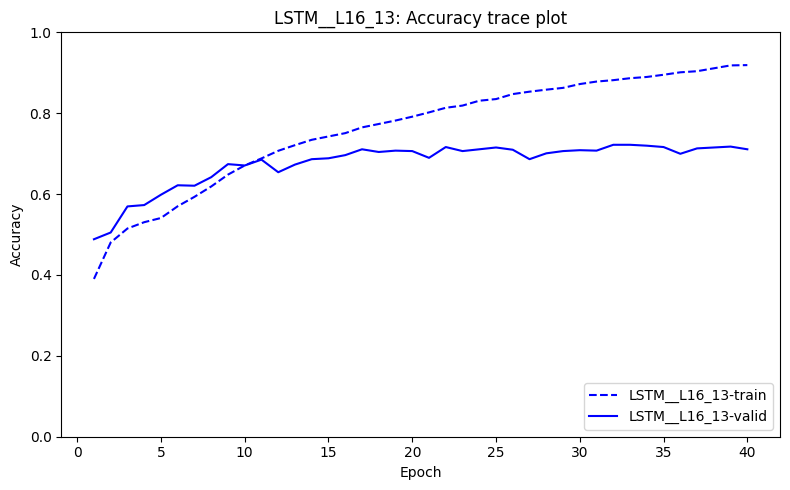

In [31]:
result_lstm_13 = run_design('LSTM', 13)


## LSTM — 조합 14

LSTM__L16_14 학습 시작: {'max_len': 200, 'layers': 1, 'units': 100, 'optimizer': 'RMSprop', 'num_words': 1000, 'embedding_dim': 100, 'learning_rate': 0.0001, 'batch_size': 100, 'dropout': 0.0, 'epochs': 40}


  epoch 5: 검증 정확도=41.82%


  epoch 10: 검증 정확도=52.61%


  epoch 15: 검증 정확도=59.62%


  epoch 20: 검증 정확도=59.73%


  epoch 25: 검증 정확도=59.96%


  epoch 30: 검증 정확도=60.85%


  epoch 35: 검증 정확도=62.29%


  epoch 40: 검증 정확도=63.85%


LSTM__L16_14: 검증=63.85%, 테스트=60.28%, 손실=1.6237, 시간=22017.9초


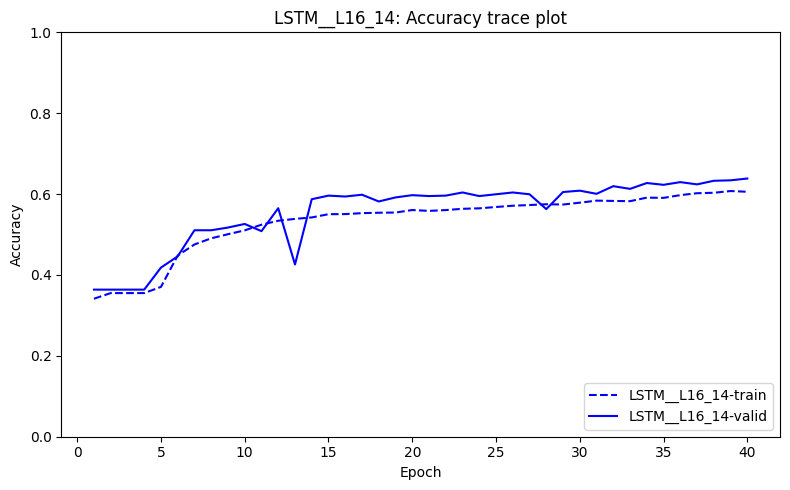

In [32]:
result_lstm_14 = run_design('LSTM', 14)


## LSTM — 조합 15

LSTM__L16_15 학습 시작: {'max_len': 100, 'layers': 2, 'units': 100, 'optimizer': 'RMSprop', 'num_words': 5000, 'embedding_dim': 32, 'learning_rate': 0.0001, 'batch_size': 100, 'dropout': 0.2, 'epochs': 20}


  epoch 5: 검증 정확도=52.17%


  epoch 10: 검증 정확도=56.62%


  epoch 15: 검증 정확도=56.28%


  epoch 20: 검증 정확도=55.17%


LSTM__L16_15: 검증=55.17%, 테스트=52.14%, 손실=1.7714, 시간=215.7초


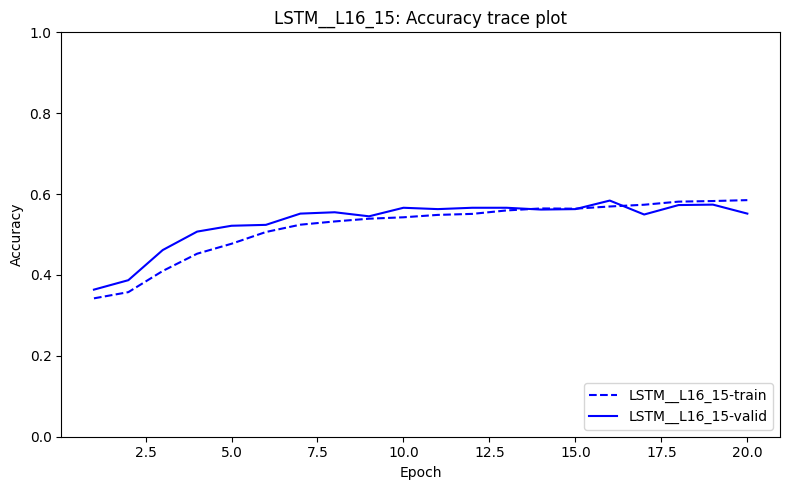

In [33]:
result_lstm_15 = run_design('LSTM', 15)


## LSTM — 조합 16

LSTM__L16_16 학습 시작: {'max_len': 200, 'layers': 2, 'units': 50, 'optimizer': 'RMSprop', 'num_words': 1000, 'embedding_dim': 32, 'learning_rate': 0.001, 'batch_size': 100, 'dropout': 0.0, 'epochs': 20}


  epoch 5: 검증 정확도=58.51%


  epoch 10: 검증 정확도=63.63%


  epoch 15: 검증 정확도=64.52%


  epoch 20: 검증 정확도=69.08%


LSTM__L16_16: 검증=69.08%, 테스트=65.81%, 손실=1.4017, 시간=272.6초


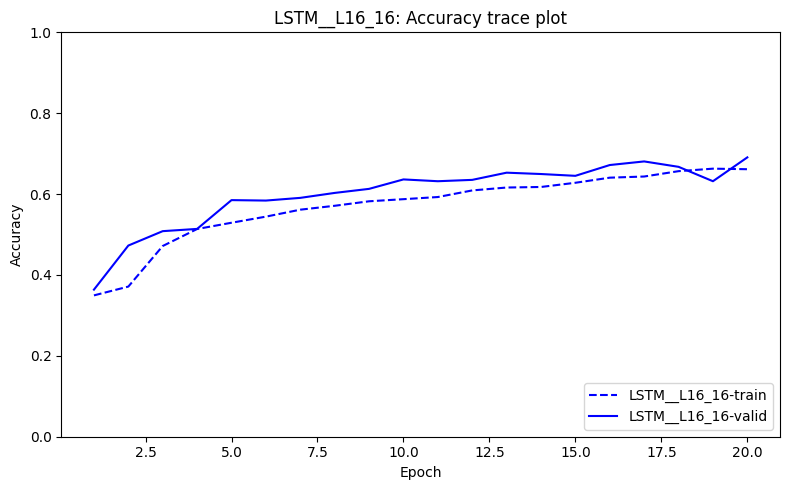

In [34]:
result_lstm_16 = run_design('LSTM', 16)


## 수준별 평균 검증 정확도 및 확인 실험 조합 선정

In [35]:
screen = pd.DataFrame([r for r in RESULTS.values() if r['phase'] == 'L16'])
assert len(screen) == 32
display(screen[['model_name', 'val_accuracy', 'val_loss', 'test_accuracy', 'test_loss', 'seconds']])
SUGGESTED = {}
effects = []
for family in ['RNN', 'LSTM']:
    subset = screen[screen.model_type == family]
    config = {}
    for key, values in LEVELS.items():
        means = [float(subset.loc[subset[key] == value, 'val_accuracy'].mean()) for value in values]
        selected = int(np.argmax(means))
        config[key] = values[selected]
        effects.append(dict(model_type=family, parameter=key,
                            level_1=values[0], mean_val_1=means[0],
                            level_2=values[1], mean_val_2=means[1],
                            selected=values[selected], difference_pp=100 * (means[1] - means[0])))
    SUGGESTED[family] = config
effects_df = pd.DataFrame(effects)
display(effects_df)
effects_df.to_csv(OUTPUT / 'level_effects.csv', index=False, encoding='utf-8-sig')
(OUTPUT / 'suggested_configs.json').write_text(json.dumps(SUGGESTED, indent=2), encoding='utf-8')
print('검증 정확도 평균으로 선택한 확인 실험 설정:')
print(json.dumps(SUGGESTED, indent=2))


,model_name,val_accuracy,val_loss,test_accuracy,test_loss,seconds
0,RNN__L16_01,0.580645,1.672087,0.545859,1.799342,33.658979
1,RNN__L16_02,0.521691,1.773792,0.480410,1.941570,91.802450
2,RNN__L16_03,0.529477,3.646801,0.480855,4.091540,151.503386
3,RNN__L16_04,0.599555,2.168848,0.566785,2.227841,368.535356
4,RNN__L16_05,0.552836,2.407893,0.530276,2.553056,64.108656
5,RNN__L16_06,0.626251,1.501267,0.596616,1.647242,112.693539
6,RNN__L16_07,0.569522,2.019132,0.549866,2.059899,205.414455
7,RNN__L16_08,0.536151,2.809794,0.488869,3.050050,353.270888
8,RNN__L16_09,0.592881,1.649920,0.564559,1.767675,46.188821
9,RNN__L16_10,0.497219,3.126126,0.445236,3.512440,129.614601


,model_type,parameter,level_1,mean_val_1,level_2,mean_val_2,selected,difference_pp
0,RNN,max_len,100,0.568409,200,0.575222,200,0.681315
1,RNN,layers,1,0.578420,2,0.565211,1,-1.320913
2,RNN,units,50,0.575501,100,0.568131,50,-0.736930
3,RNN,optimizer,Adam,0.557981,RMSprop,0.585651,RMSprop,2.766963
4,RNN,num_words,1000,0.578420,5000,0.565211,1000,-1.320911
5,RNN,embedding_dim,32,0.555339,100,0.588293,100,3.295328
6,RNN,learning_rate,0.0001,0.603587,0.001,0.540044,0.0001,-6.354282
7,RNN,batch_size,32,0.564516,100,0.579116,100,1.459955
8,RNN,dropout,0.0,0.568826,0.2,0.574805,0.2,0.597887
9,RNN,epochs,20,0.571051,40,0.572581,40,0.152948


검증 정확도 평균으로 선택한 확인 실험 설정:
{
  "RNN": {
    "max_len": 200,
    "layers": 1,
    "units": 50,
    "optimizer": "RMSprop",
    "num_words": 1000,
    "embedding_dim": 100,
    "learning_rate": 0.0001,
    "batch_size": 100,
    "dropout": 0.2,
    "epochs": 40
  },
  "LSTM": {
    "max_len": 200,
    "layers": 1,
    "units": 50,
    "optimizer": "Adam",
    "num_words": 1000,
    "embedding_dim": 100,
    "learning_rate": 0.001,
    "batch_size": 32,
    "dropout": 0.0,
    "epochs": 40
  }
}


## RNN — 수준 평균으로 선정한 조합의 확인 실험

RNN__confirmation_best_levels 학습 시작: {'max_len': 200, 'layers': 1, 'units': 50, 'optimizer': 'RMSprop', 'num_words': 1000, 'embedding_dim': 100, 'learning_rate': 0.0001, 'batch_size': 100, 'dropout': 0.2, 'epochs': 40}


  epoch 5: 검증 정확도=38.60%


  epoch 10: 검증 정확도=48.83%


  epoch 15: 검증 정확도=54.39%


  epoch 20: 검증 정확도=56.06%


  epoch 25: 검증 정확도=58.95%


  epoch 30: 검증 정확도=60.51%


  epoch 35: 검증 정확도=62.63%


  epoch 40: 검증 정확도=62.63%


RNN__confirmation_best_levels: 검증=62.63%, 테스트=58.86%, 손실=1.6620, 시간=97.3초


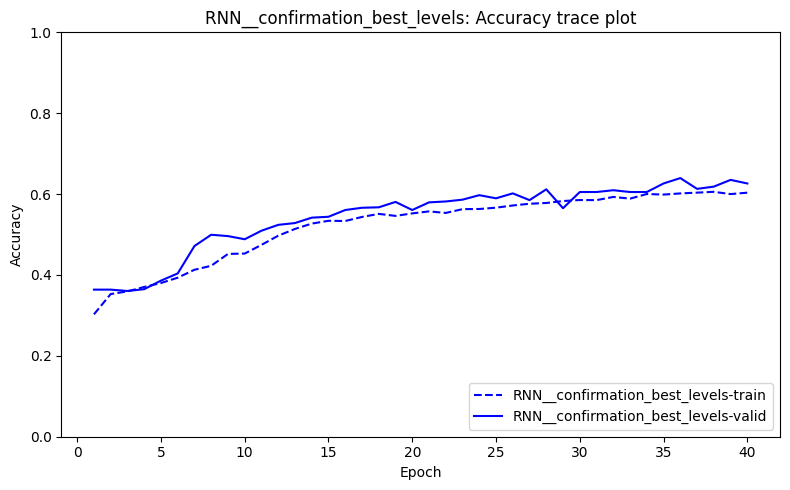

In [36]:
confirmation_rnn = run_one('RNN', 'best_levels', SUGGESTED['RNN'], phase='confirmation')


## LSTM — 수준 평균으로 선정한 조합의 확인 실험

LSTM__confirmation_best_levels 학습 시작: {'max_len': 200, 'layers': 1, 'units': 50, 'optimizer': 'Adam', 'num_words': 1000, 'embedding_dim': 100, 'learning_rate': 0.001, 'batch_size': 32, 'dropout': 0.0, 'epochs': 40}


  epoch 5: 검증 정확도=65.85%


  epoch 10: 검증 정확도=70.63%


  epoch 15: 검증 정확도=75.64%


  epoch 20: 검증 정확도=76.86%


  epoch 25: 검증 정확도=79.87%


  epoch 30: 검증 정확도=79.20%


  epoch 35: 검증 정확도=79.98%


  epoch 40: 검증 정확도=78.20%


LSTM__confirmation_best_levels: 검증=78.20%, 테스트=73.02%, 손실=1.4428, 시간=322.8초


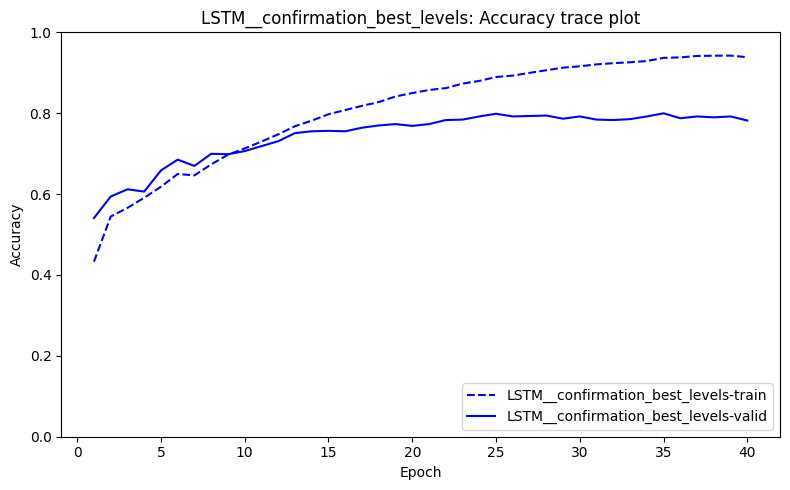

In [37]:
confirmation_lstm = run_one('LSTM', 'best_levels', SUGGESTED['LSTM'], phase='confirmation')


## 전체 결과 표 및 Markdown 저장

In [38]:
final = pd.DataFrame(RESULTS.values())
display(final[['model_name', 'val_accuracy', 'val_loss', 'test_accuracy', 'test_loss', 'seconds']])
lines = ['# 다구치 L16 실험 결과', '',
         '설정 선택은 마지막 epoch의 검증 정확도로 수행했습니다. 테스트 결과는 참고 평가값입니다.', '',
         '| 모델명 | 검증 정확도 | 테스트 정확도 | 테스트 손실 | 시간(초) |',
         '|---|---:|---:|---:|---:|']
for row in RESULTS.values():
    lines.append(f"| {row['model_name']} | {row['val_accuracy']:.2%} | {row['test_accuracy']:.2%} | {row['test_loss']:.4f} | {row['seconds']:.1f} |")
lines += ['', '## 모델별 검증 성능 비교', '']
for family in ['RNN', 'LSTM']:
    subset = final[(final.model_type == family) & (final.phase == 'L16')]
    best = subset.sort_values(['val_accuracy', 'val_loss'], ascending=[False, True]).iloc[0]
    confirm = final[(final.model_type == family) & (final.phase == 'confirmation')].iloc[0]
    lines.append(f"- {family}: L16 중 검증 최고는 {best['model_name']} (검증 {best['val_accuracy']:.2%}, 테스트 {best['test_accuracy']:.2%}). 수준 평균 조합의 확인 실험은 검증 {confirm['val_accuracy']:.2%}, 테스트 {confirm['test_accuracy']:.2%}.")
lines += ['', '수준 평균으로 예측한 조합이 실제 최고 조합과 일치한다고 보장하지 않습니다. 단일 시드 실행이며 모든 상호작용을 분리할 수 없습니다. 이미 살펴본 테스트 데이터이므로 독립적인 최종 평가로 해석하지 않습니다.']
(OUTPUT / '다구치_실험결과.md').write_text('\n'.join(lines) + '\n', encoding='utf-8')


,model_name,val_accuracy,val_loss,test_accuracy,test_loss,seconds
0,RNN__L16_01,0.580645,1.672087,0.545859,1.799342,33.658979
1,RNN__L16_02,0.521691,1.773792,0.480410,1.941570,91.802450
2,RNN__L16_03,0.529477,3.646801,0.480855,4.091540,151.503386
3,RNN__L16_04,0.599555,2.168848,0.566785,2.227841,368.535356
4,RNN__L16_05,0.552836,2.407893,0.530276,2.553056,64.108656
5,RNN__L16_06,0.626251,1.501267,0.596616,1.647242,112.693539
6,RNN__L16_07,0.569522,2.019132,0.549866,2.059899,205.414455
7,RNN__L16_08,0.536151,2.809794,0.488869,3.050050,353.270888
8,RNN__L16_09,0.592881,1.649920,0.564559,1.767675,46.188821
9,RNN__L16_10,0.497219,3.126126,0.445236,3.512440,129.614601


2252